# Simulation examples

This notebook shows the current simulator API in two settings:

- one episode, step by step
- many episodes, with density mean and standard deviation


## Imports


In [1]:
import sys
from pathlib import Path

import igraph as ig
import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")

from network_creation.core.agent import Agent
from network_creation.core.environment import Environment
from network_creation.core.graph import create_empty_graph
from network_creation.core.model import ActorScheduler
from network_creation.core.observability import ObservationSampling
from network_creation.core.simulator import Simulator
from network_creation.observers.grimoire import OBSERVER_GRIMOIRE
from network_creation.plotting.episode_series import plot_episode_series_observer
from network_creation.plotting.graph_history import (
    build_circle_layout,
    plot_graph_history,
)
from network_creation.policies.random import RandomPolicy
from network_creation.policies.best_response import BestResponsePolicy

ActionPrintObserver = OBSERVER_GRIMOIRE["action_print"]
DensityObserver = OBSERVER_GRIMOIRE["density"]
StateHistoryObserver = OBSERVER_GRIMOIRE["state_history"]
NormalizedWelfareObserver = OBSERVER_GRIMOIRE["normalized_welfare"]

## Single episode


In [ ]:
initial_graph_adj = np.array(
    [
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0],
    ],
    dtype=np.int8,
)
init_graph = ig.Graph.Adjacency(initial_graph_adj.tolist(), mode=ig.ADJ_DIRECTED)
fixed_layout = build_circle_layout(n_nodes=initial_graph_adj.shape[0])

env = Environment(graph=init_graph, seed=11)
fixed_layout = build_circle_layout(n_nodes=initial_graph_adj.shape[0])

agents = tuple(
    Agent(
        id=node_id,
        visibility_distance=2,
        policy=BestResponsePolicy(
            n_nodes=initial_graph_adj.shape[0],
            seed=11 + node_id,
            benefit_to_cost_ratio=0.5,
            distance_discount=0.9,
            bridge_weight=0.0,
            pass_bias=0.5,
            exploration=0.54,
            opportunity_sensitivity=0.5,
        ),
        seed=42 + node_id,
    )
    for node_id in range(initial_graph_adj.shape[0])
)

max_steps = 10
simulator_seed = 301
actor_scheduler = ActorScheduler(n_agents=initial_graph_adj.shape[0], n_actors=1, seed=simulator_seed)

action_printer = ActionPrintObserver(
    observation_sampling=ObservationSampling.periodic(1), print_empty_steps=False
)
state_history_observer = StateHistoryObserver(
    observation_sampling=ObservationSampling.periodic(1), keep_runs=False
)

In [ ]:
simulator = Simulator(
    env=env,
    agents=agents,
    actor_scheduler=actor_scheduler,
    max_steps=max_steps,
    rng=np.random.default_rng(simulator_seed),
    observers=(action_printer, state_history_observer),
)

simulator.run(n_episodes=1, reset_observers=False)

### Directed graph after each sampled step


In [ ]:
plot_graph_history(
    steps=state_history_observer.steps,
    graphs=state_history_observer.graphs,
    layout=fixed_layout,
    figure_title="Directed graph over one episode",
    max_cols=4,
)
plt.show()

## Multiple episodes

The simulator now derives a fresh seed for each agent at each episode.
That keeps repeated runs reproducible while avoiding identical random episodes.


In [ ]:
{'benefit_to_cost_ratio': np.float32(0.1),
 'distance_discount': np.float32(0.9),
 'bridge_weight': np.float32(0.6618693),
 'pass_bias': np.float32(0.41538683),
 'exploration': np.float32(0.0012657074),
 'opportunity_sensitivity': np.float32(0.4204412),
 'visibility_distance': np.float32(3.0)}

In [6]:
n_agents = 50
multi_env = Environment(graph=create_empty_graph(n_agents=n_agents), seed=101)
multi_agents = tuple(
    Agent(
        id=node_id,
        visibility_distance=3,
        policy=BestResponsePolicy(
            n_nodes=n_agents,
            seed=11 + node_id,
            benefit_to_cost_ratio=0.1,
            distance_discount=0.9,
            bridge_weight=0.6618693,
            pass_bias=0.41538683,
            exploration=0.0012657074,
            opportunity_sensitivity=0.4204412,
        ),
        seed=500 + node_id,
    )
    for node_id in range(multi_env.state.graph.vcount())
)
multi_density_observer = NormalizedWelfareObserver(
    observation_sampling=ObservationSampling.periodic(1),
    aggregations=("mean", "std", "runs"),
    benefit_to_cost_ratio=0.1,
    distance_discount=0.9,
)
state_history_observer = StateHistoryObserver(
    observation_sampling=ObservationSampling.periodic(1), keep_runs=True
)
action_printer = ActionPrintObserver(observation_sampling=ObservationSampling.periodic(1), print_empty_steps=False)

multi_simulator = Simulator(
    env=multi_env,
    agents=multi_agents,
    actor_scheduler=ActorScheduler(n_agents=len(multi_agents), n_actors=1, seed=41),
    max_steps=500,
    rng=np.random.default_rng(41),
    observers=(multi_density_observer, state_history_observer, action_printer),
)

multi_simulator.run(n_episodes=10, reset_observers=True)
multi_density_result = multi_density_observer.get()
state_history_result = state_history_observer.get()

multi_density_result.n_episodes, tuple(multi_density_result.outputs)


step 1
  33: BRIDGE->15 (value={value=0.3})

step 2
  47: PASS (value={value=0.33})

step 3
  41: BRIDGE->9 (value={value=0.3})

step 4
  38: PASS (value={value=0.33})

step 5
  35: PASS (value={value=0.33})

step 6
  6: PASS (value={value=0.33})

step 7
  12: BRIDGE->37 (value={value=0.3})

step 8
  41: PASS (value={value=0.33})

step 9
  16: BRIDGE->43 (value={value=0.3})

step 10
  42: BRIDGE->12 (value={value=0.3})

step 11
  8: BRIDGE->7 (value={value=0.3})

step 12
  17: BRIDGE->5 (value={value=0.3})

step 13
  48: BRIDGE->43 (value={value=0.3})

step 14
  25: PASS (value={value=0.33})

step 15
  41: BRIDGE->7 (value={value=0.27})

step 16
  30: BRIDGE->23 (value={value=0.3})

step 17
  3: BRIDGE->15 (value={value=0.3})

step 18
  16: BRIDGE->12 (value={value=0.24})

step 19
  25: PASS (value={value=0.33})

step 20
  31: PASS (value={value=0.33})

step 21
  49: BRIDGE->38 (value={value=0.3})

step 22
  36: PASS (value={value=0.33})

step 23
  16: BRIDGE->38 (value={value=0.16})


(10, ('mean', 'std', 'runs'))

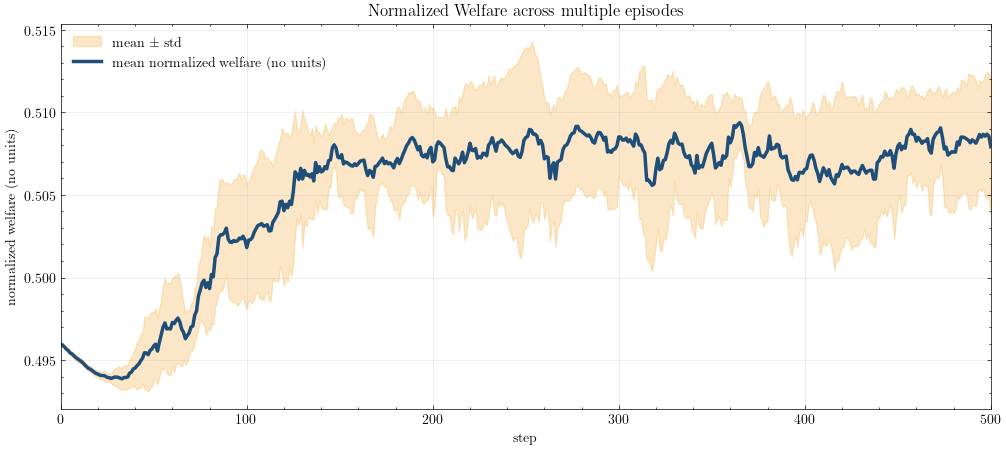

In [7]:
figure, axis = plt.subplots(figsize=(12, 5))
plot_episode_series_observer(observer=multi_density_observer, ax=axis)
plt.show()

In [ ]:
from netgraph import Graph
import networkx as nx
import matplotlib as mpl

def draw_network(graph:nx.DiGraph):
    node_labels = {n: str(n) for n in graph.nodes()}
    mpl.rcParams.update(mpl.rcParamsDefault)
    _, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,8), dpi=120)
    return Graph(
        graph=graph, 
        node_labels=node_labels, 
        edge_label_fontdict=dict(size=8, fontweight='normal', color="b", bbox=dict(boxstyle='round', ec=(1.0, 1.0, 1.0), fc=(1.0, 1.0, 1.0), alpha=0.9)),
        node_layout='spring', 
        node_layout_kwargs={'pad_by': 0.01},
        edge_layout='curved',
        node_shape='o',
        node_label_fontdict = dict(size=8, fontweight='normal'),
        node_size=3, 
        edge_width=0.5, 
        edge_color='#d111b7',
        arrows=True, 
        ax=ax)

res = draw_network(state_history_result.graphs[-1].to_networkx(vertex_attr_hashable="name"))
res

In [4]:
from netgraph import Graph
import networkx as nx
import matplotlib as mpl
from netgraph import InteractiveGraph

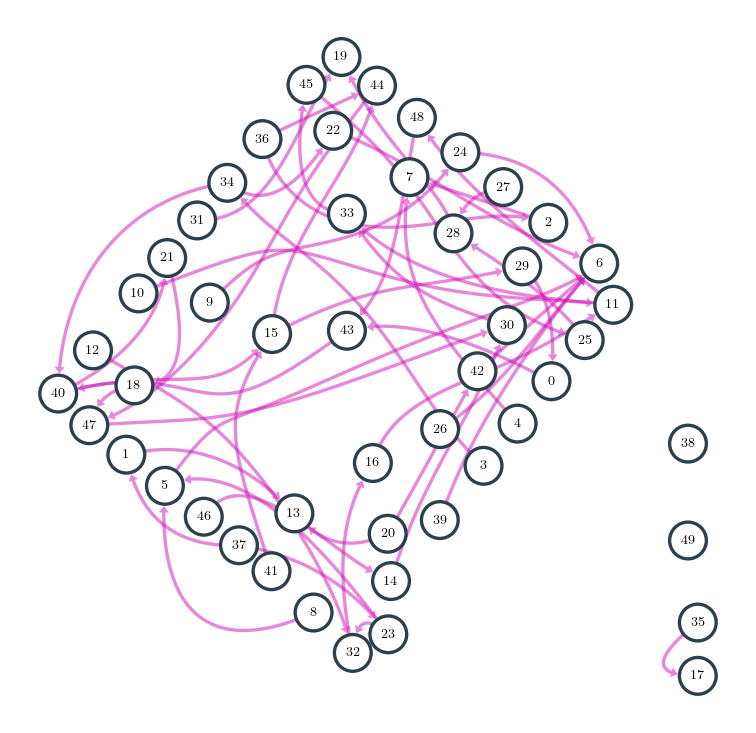

In [5]:
%matplotlib ipympl

g = state_history_result.graphs[-1].to_networkx(vertex_attr_hashable="name")

_, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,8), dpi=120)

node_labels = {n: str(n) for n in g.nodes()}
plot_instance = InteractiveGraph(
    g, 
    node_labels=node_labels, 
    edge_label_fontdict=dict(size=8, fontweight='normal', color="b", bbox=dict(boxstyle='round', ec=(1.0, 1.0, 1.0), fc=(1.0, 1.0, 1.0), alpha=0.9)),
    node_layout='spring', 
    node_layout_kwargs={'pad_by': 0.01, "k":0.3},
    edge_layout='curved',
    node_shape='o',
    node_label_fontdict = dict(size=8, fontweight='normal'),
    node_size=3, 
    edge_width=0.5, 
    edge_color='#d111b7',
    arrows=True, 
    ax=ax)

plt.show()

In [ ]:
num_runs = 6
fixed_layout = build_circle_layout(n_nodes=n_agents)
plot_graph_history(
    steps=np.arange(num_runs),
    graphs=state_history_observer._runs_graphs[0][-num_runs:],
    layout=lambda g: draw_shell(g),
    figure_title="",
    max_cols=3,
)
plt.show()

In [ ]:
num_runs = 10
fixed_layout = build_circle_layout(n_nodes=n_agents)
plot_graph_history(
    steps=np.arange(num_runs),
    graphs=[graphs_run[-1] for graphs_run in state_history_observer._runs_graphs][:num_runs],
    layout=fixed_layout,
    figure_title="",
    max_cols=4,
)
plt.show()